# Regression

## Linear Regression

**Linear relationship between independent (input feature) and dependent (target).   
  single input feature is called simple regression  
  more than one feature multiple linear regression  
  y = wx +b, we have to found w, b  
  w is slope or weight and b is intercpt or bias  
   Loss function (mean squared error)  
  J(w,b) = 1/n(sum (yi - (wxi+b))^2)**  

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
np.random.seed(42)
X = 2*np.random.rand(100,1)
y = 3*X+4+np.random.rand(100,1)

In [4]:
# convert data to dataframe
data = pd.DataFrame({'X': X.flatten(), 'y': y.flatten()})
data

,X,y
0,0.749080,6.278670
1,1.901429,10.340696
2,1.463988,8.706320
3,1.197317,8.100522
4,0.312037,5.843678
...,...,...
95,0.987591,7.311983
96,1.045466,7.862353
97,0.855082,7.462356
98,0.050838,5.039601


Text(0, 0.5, 'y')

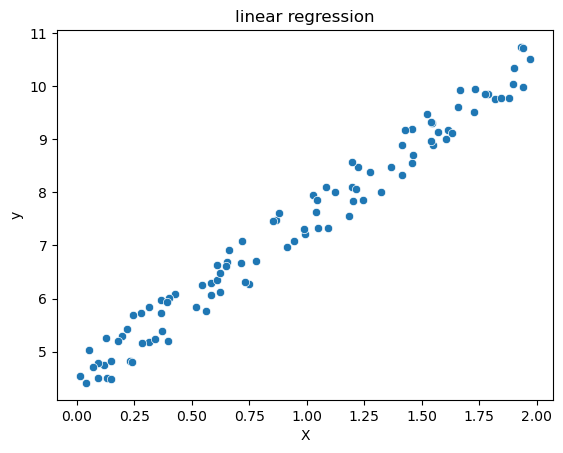

In [5]:
# scatter plot
sns.scatterplot(x = 'X', y = 'y', data=data)
plt.title("linear regression")
plt.xlabel("X")
plt.ylabel("y")

In [6]:
# manual calculation of w and b
x_mean = X.mean()
y_mean = y.mean()

In [7]:

numerator = np.sum((X-x_mean)*(y-y_mean))
denominater = np.sum((X-x_mean)**2)

w = numerator / denominater
b = y_mean -w * x_mean

print(f"Estimated weight : {w: .4f}")
print(f"Estimated bias : {b: .4f}")

Estimated weight :  2.9832
Estimated bias :  4.5136


In [8]:
# prediction
y_pred_manual = w*X + b

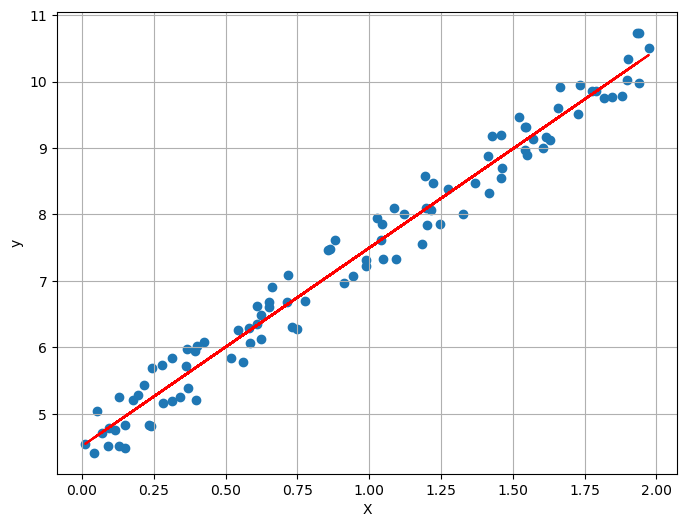

In [9]:
plt.figure(figsize=(8,6))
plt.scatter(X,y, label = 'actual')
plt.plot(X, y_pred_manual, color = 'red', label = 'manual prediction')
plt.xlabel('X')
plt.ylabel('y')
plt.grid()


## linear regression in scikit-learn

In [10]:
from sklearn.linear_model import LinearRegression

In [11]:
# Fit model
model = LinearRegression()
model.fit(X, y)

print(f"sklearn Weight (w): {model.coef_[0][0]:.4f}")
print(f"sklearn bias (b): {model.intercept_[0]:.4f}")
# 
y_pred_sklearn = model.predict(X)

sklearn Weight (w): 2.9832
sklearn bias (b): 4.5136


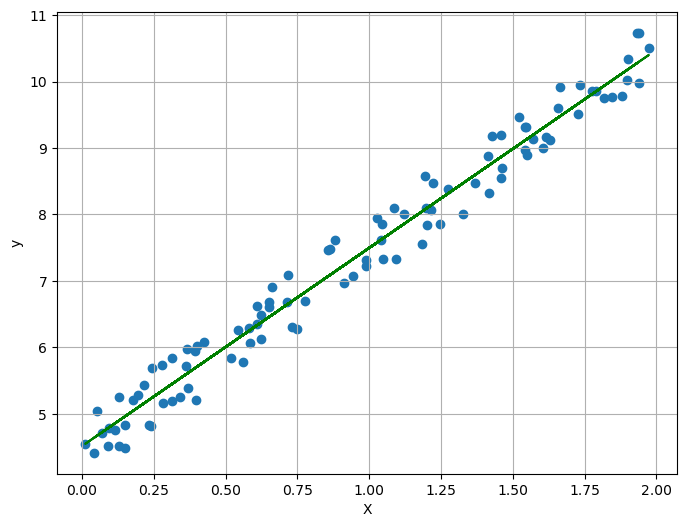

In [12]:
plt.figure(figsize=(8,6))
plt.scatter(X,y, label = 'actual')
plt.plot(X,y_pred_sklearn , color = 'green', label = 'manual prediction')
plt.xlabel('X')
plt.ylabel('y')
plt.grid()

## Evaluation metrices

we evaluate the model using 
Mean squared Error (MSE)

In [13]:
from sklearn.metrics import mean_squared_error

mse = mean_squared_error(y, y_pred_sklearn)
print(f"Mean squared error: {mse: .4f}")

Mean squared error:  0.0850


## Multiple Linear Regression

In [14]:
# y = 3x1 +5x2 + 4+ noise
np.random.seed(42)
x1 = 2*np.random.rand(100,1)
x2 = 2*np.random.rand(100,1)
b_true = 4
w1_true = 3
w2_true = 5
y = 3*x1 + 5*x2+4+np.random.rand(100,1)

In [15]:
#y = w1